# TSARA, Phase 7c1 — the ratio stage's fits

**A walkthrough you can run, change and try to break.** Every number and figure
below is produced by the package from air this notebook manufactures with a
plain recipe, so the right answer is always known: which source each part of
every plume came from, and its true ratio. No real measurement is read.

---

## How to use this notebook

1. **Run everything once** (*Run All*, a few minutes).
2. **Every section stands on its own.** Each opens with a **parameters cell**:
   a short list of CAPITALISED names, each commented with what it controls.
   Change a value, then run that section's cells from the parameters cell down
   to the next heading. Sections share only the setup cell below.
3. **Checks.** A line beginning ✔ is a claim about TSARA, compared *as it ran*
   against something written independently here: a plain loop written from
   the definition in `METHODS.md`, or the truth the recipe manufactured. The
   checks are written to hold at *any* parameters. If you see ✘, you have
   found an edge case worth understanding or a bug.
4. **"Try it"** notes after each section suggest a change and say what should
   happen. Each prediction was run before this notebook was committed.
5. **The last section** collects every check into one scoreboard.

---

## What this phase delivers

Phase 7b grouped each window's events into **candidates**. 7c1 fits a line
through each of them: every numerator against its reference, once per
member, with every number the gates will read (`METHODS.md` §5.2–5.4). The
ratio a candidate reports, its combined uncertainty and the sweep summary
are 7c2's.

| | Property | Section |
|---|---|---|
| 1 | **Which points a fit gets**: a candidate's members, and the pair cells whose midpoint each holds | §1 |
| 2 | **Two instruments on one clock**: the pair clock, the sweep paired point by point, the readings carried | §2 |
| 3 | **One member's line**, York beside least squares, and every number stored with it | §3 |
| 4 | **The slope's sigma widened** for errors that persist, and by the scatter: Monte Carlo | §4 |
| 5 | **The gates as numbers**, and the plateau's trade: purer, at half the good members | §5 |
| 6 | **What the widened sigma does not hold**: the baseline's error across a member | §6 |

What this part does **not** do: report a candidate's ratio, combine the
uncertainties, or summarize the sweep (7c2), or read a real campaign (7c3).

---

## Vocabulary used throughout

| term | meaning |
|---|---|
| **reference** | the denominator gas, named `<instrument>.<variable>`; its candidates are the stretches every fit is over |
| **numerator** | a gas fitted against the reference |
| **enhancement** | a reading minus its baseline at one window and quantile (one value per sweep point) |
| **event** | an interval the events stage reported at one sweep point (window, quantile, entry, exit) |
| **candidate** | one window's events across quantile, entry and exit that share a peak (§6.8) |
| **member** | one of a candidate's distinct (quantile, exit) intervals: the events at several entries share one, so each member is fitted once |
| **pair cell** | a cell of the pair clock holding both gases' enhancements; on one instrument, its own cells |
| **fit** | one line through the pair cells of one member |

---
## Setup (run this cell first)

The **toolkit**: imports, the figure style shared by notebooks 01–09, the
**reference implementations** the checks compare TSARA against, the
scoreboard, and the **recipe** that manufactures air.

In [1]:
# =============================================================================
# TOOLKIT. Every section needs this cell and nothing else from other sections.
# =============================================================================
import logging
import math
from functools import cache

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from scipy.stats import chi2

from tsara.align import pair_species
from tsara.baseline import baseline_state
from tsara.config.analysis import BaselineConfig, EventsConfig
from tsara.core.timebase import SECOND_NS
from tsara.events import event_catalog, event_states
from tsara.ratios import PairColumns, member_fits, ols, york

logging.disable(logging.WARNING)  # the stages' warnings are about this made-up air

# --- 1. figure style (identical to notebooks 01-08) --------------------------
C1, C2, C3 = "#0072b2", "#e69f00", "#009e73"  # Okabe-Ito blue, amber, green: colour-blind safe
C4 = "#cc79a7"  # Okabe-Ito purple, for a fourth series
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, SURFACE = "#e1e0d9", "#fcfcfb"
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "axes.edgecolor": "#c3c2b7",
        "axes.linewidth": 0.8,
        "axes.labelcolor": INK2,
        "axes.titlecolor": INK,
        "axes.titlesize": 11,
        "axes.titleweight": "normal",
        "axes.titlelocation": "left",
        "axes.labelsize": 9.5,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "xtick.labelsize": 8.5,
        "ytick.labelsize": 8.5,
        "grid.color": GRID,
        "grid.linewidth": 0.7,
        "grid.linestyle": "-",
        "legend.frameon": False,
        "legend.fontsize": 9,
        "font.size": 9.5,
        "lines.linewidth": 1.4,
        "figure.dpi": 110,
    }
)


def finish(
    ax, title=None, sub=None, ylab=None, xlab=None, legend=False, grid_axis="y", loc="upper right"
):
    """Apply the shared chrome: left-aligned title, muted subtitle, hairline grid."""
    if title:
        ax.set_title(title, pad=19 if sub else 8)
    if sub:
        ax.text(0, 1.025, sub, transform=ax.transAxes, fontsize=8.8, color=MUTED, va="bottom")
    if ylab:
        ax.set_ylabel(ylab)
    if xlab:
        ax.set_xlabel(xlab)
    if grid_axis:
        ax.grid(True, axis=grid_axis, alpha=0.9)
    ax.set_axisbelow(True)
    if legend:
        ax.legend(loc=loc)


def clock(ax, fmt="%H:%M"):
    """Label a time axis in hours and minutes, or in the format given."""
    ax.xaxis.set_major_formatter(mdates.DateFormatter(fmt))


# --- 2. reference implementations --------------------------------------------
# Written from METHODS.md §5.2, deliberately slow and plain, one value at a
# time. They share no code with TSARA.


def reference_members(catalog, instrument, variable):
    """Return the members by a plain loop: {(candidate, quantile, exit): its lowest entry's row}."""
    members = {}
    for row in catalog.itertuples():
        if row.instrument != instrument or row.species != variable:
            continue
        key = (row.candidate_id, row.baseline_quantile, row.exit_multiple)
        if key not in members or row.enter_multiple < members[key].enter_multiple:
            members[key] = row
    return members


def reference_points(midpoints_ns, start_ns, end_ns):
    """Return the indices of the pair cells a member holds: start <= midpoint < end, by a loop."""
    return [i for i, mid in enumerate(midpoints_ns) if start_ns <= mid < end_ns]


def reference_join(reading_bounds_ns, values, sigmas, cell_start_ns, cell_stop_ns):
    """Return one cell's overlap-weighted mean of readings and its sigma, by a plain loop.

    Each reading's weight is the time it shares with the cell; the mean is
    sum(w v) / sum(w) over finite readings, and its random sigma, for
    independent readings, sqrt(sum(w^2 sigma^2)) / sum(w) (METHODS.md §3.2).
    """
    weight_sum, value_sum, variance_sum = 0.0, 0.0, 0.0
    for (start, stop), value, sigma in zip(reading_bounds_ns, values, sigmas):
        overlap = min(stop, cell_stop_ns) - max(start, cell_start_ns)
        if overlap > 0 and np.isfinite(value):
            weight_sum += overlap
            value_sum += overlap * value
            variance_sum += (overlap * sigma) ** 2
    if weight_sum == 0:
        return np.nan, np.nan
    return value_sum / weight_sum, math.sqrt(variance_sum) / weight_sum


def reference_n_effective(n, spacing_s, tau_s):
    """Return N_eff for n AR(1) points, rho = exp(-spacing/tau), by its sum (METHODS §3.4).

    N_eff = n / (1 + 2 sum_{k=1}^{n-1} (1 - k/n) rho^k), the variance of a mean
    of n equally weighted correlated points expressed as a count.
    """
    rho = math.exp(-spacing_s / tau_s)
    total = sum((1 - k / n) * rho**k for k in range(1, n))
    return n / (1 + 2 * total)


def mswd_gate(dof, probability=0.99):
    """Return the largest MSWD a one-source fit passes: the chi-squared quantile over its dof."""
    dof = np.asarray(dof, dtype=float)
    return np.where(dof > 0, chi2.ppf(probability, np.maximum(dof, 1)) / np.maximum(dof, 1), np.nan)


def source_share(fits, truth, pairs):
    """Return per fit source A's share of its points' true methane, and their largest true plume.

    The truth the recipe kept: a member is *single* A at a share of at least
    0.95, single B at 0.05 or less, a *mixture* between (METHODS.md §5.3).
    """
    mid = pairs.time.values.astype("datetime64[ns]").astype(np.int64)
    first = np.searchsorted(mid, fits.start_time.values.astype("datetime64[ns]").astype(np.int64))
    last = np.searchsorted(mid, fits.end_time.values.astype("datetime64[ns]").astype(np.int64))
    a, b = (np.concatenate([[0.0], np.cumsum(truth[k])]) for k in ("A", "B"))
    sum_a, sum_b = a[last] - a[first], b[last] - b[first]
    share = np.where(sum_a + sum_b > 0, sum_a / np.maximum(sum_a + sum_b, 1e-300), np.nan)
    both = truth["A"] + truth["B"]
    largest = np.array([both[i:j].max() if j > i else 0.0 for i, j in zip(first, last)])
    return share, largest


def kind_of(share, largest):
    """Name each fit's truth: 'A', 'B', 'mixture', or 'none' (no true plume of 0.7 ppb in it)."""
    return np.where(
        largest < 0.7, "none", np.where(share >= 0.95, "A", np.where(share <= 0.05, "B", "mixture"))
    )


def pairs_by_hand(dx, dy, sigma_x, sigma_y, tau=None):
    """Return a paired product made directly from enhancements on 1 s cells, one sweep point.

    For sections that study the line alone, apart from the baseline: the
    enhancements are handed to the fit as they are, with the readings'
    sigmas and, if given, a decorrelation time declared on both.
    """
    n = dx.size
    start = START.value + np.arange(n, dtype=np.int64) * SECOND_NS
    swept = ("time", "baseline_window", "baseline_quantile")
    attrs = {"units": "ppb", "tsara_instrument": "van"}
    if tau is not None:
        attrs = {**attrs, "decorrelation_timescale": tau}
    data = {
        "enhancement_ch4": (swept, dx[:, None, None], attrs),
        "enhancement_c2h6": (swept, dy[:, None, None], attrs),
        "borrowed_enhancement_ch4": (swept, np.zeros((n, 1, 1)), {}),
        "borrowed_enhancement_c2h6": (swept, np.zeros((n, 1, 1)), {}),
        "ch4": ("time", np.zeros(n), attrs),
        "c2h6": ("time", np.zeros(n), attrs),
        "sigma_rand_ch4": ("time", np.full(n, sigma_x), {"uncertainty_provenance": "declared"}),
        "sigma_rand_c2h6": ("time", np.full(n, sigma_y), {"uncertainty_provenance": "declared"}),
    }
    pairs = xr.Dataset(
        data,
        coords={
            "time": (start + SECOND_NS // 2).astype("datetime64[ns]"),
            "time_bnds": (
                ("time", "nv"),
                np.stack([start, start + SECOND_NS], 1).astype("datetime64[ns]"),
            ),
            "baseline_window": [600.0],
            "baseline_quantile": [0.05],
        },
    )
    pairs["time"].attrs["bounds"] = "time_bnds"
    return pairs


def catalog_by_hand(spans_s):
    """Return a catalog of one-member candidates, one per (start, end) in seconds from START."""
    rows = []
    for k, (first, last) in enumerate(spans_s):
        start, end = START + pd.Timedelta(seconds=first), START + pd.Timedelta(seconds=last)
        rows.append(
            {
                "event_id": f"e{k}",
                "candidate_id": f"c{k}",
                "instrument": "van",
                "species": "ch4",
                "baseline_window": 600.0,
                "baseline_quantile": 0.05,
                "enter_multiple": 3.0,
                "exit_multiple": 1.0,
                "start_time": start,
                "peak_time": start,
                "end_time": end,
                "peak_z": 10.0,
                "trigger_event_id": None,
            }
        )
    return pd.DataFrame(rows)


HAND_COLUMNS = PairColumns("enhancement_c2h6", "enhancement_ch4", "c2h6", "ch4")


# --- 3. the scoreboard -------------------------------------------------------
CHECKS = {}


def start_section(tag):
    """Forget a section's earlier checks, so re-running it replaces rather than piles up."""
    for claim in [c for c in CHECKS if c.startswith(tag + " ")]:
        del CHECKS[claim]


def check(claim, holds, detail=""):
    """Record one claim about TSARA and print whether it held just now."""
    CHECKS[claim] = (bool(holds), detail)
    mark = "✔" if holds else "✘ DOES NOT HOLD:"
    print(f"  {mark} {claim}" + (f"   [{detail}]" if detail else ""))


# --- 4. the recipe ------------------------------------------------------------
START = pd.Timestamp("2026-01-01T00:00:00")
RATIO_A, RATIO_B = 0.05, 0.0  # ethane/methane of the two sources: a gas leak and a landfill, say


@cache
def air(seed=1, hours=1.0, plumes_per_hour=20, walk_ch4=30.0, walk_c2h6=0.6):
    """Manufacture one 1 s analyzer's methane and ethane, keeping each source's truth.

    Two sources, A at ethane/methane RATIO_A and B at RATIO_B, each making
    ``plumes_per_hour`` plumes: Gaussian in time with a width uniform on
    5-60 s, methane peaks lognormal with median 15 ppb. Backgrounds 1950 and
    2 ppb, each a random walk wandering ``walk_*`` ppb a day (0 for flat air).
    White noise 0.7 and 0.05 ppb, declared to TSARA exactly. Returns the
    stream and a dict of true series: each source's methane enhancement and
    the two backgrounds.
    """
    rng = np.random.default_rng(seed)
    n = int(hours * 3600)
    t = np.arange(n, dtype=float)
    source = {"A": np.zeros(n), "B": np.zeros(n)}
    for true in source.values():
        for _ in range(int(round(plumes_per_hour * hours))):
            centre, width = rng.uniform(0, n), rng.uniform(5, 60)
            peak = rng.lognormal(math.log(15), 0.8)
            near = slice(int(max(0, centre - 6 * width)), int(min(n, centre + 6 * width)))
            true[near] += peak * np.exp(-0.5 * ((t[near] - centre) / width) ** 2)

    def walk(per_day):
        return np.cumsum(rng.normal(0, per_day / math.sqrt(86400), n))

    background_ch4, background_c2h6 = 1950 + walk(walk_ch4), 2.0 + walk(walk_c2h6)
    ch4 = background_ch4 + source["A"] + source["B"] + rng.normal(0, 0.7, n)
    c2h6 = background_c2h6 + RATIO_A * source["A"] + RATIO_B * source["B"] + rng.normal(0, 0.05, n)
    start = START.value + np.arange(n, dtype=np.int64) * SECOND_NS
    data = {}
    for name, values, sigma in (("ch4", ch4, 0.7), ("c2h6", c2h6, 0.05)):
        data[name] = ("time", values, {"units": "ppb", "role": "gas", "cell_methods": "time: mean"})
        data["sigma_rand_" + name] = (
            "time",
            np.full(n, sigma),
            {
                "units": "ppb",
                "uncertainty_component": "random",
                "uncertainty_provenance": "declared",
            },
        )
    stream = xr.Dataset(
        data,
        coords={
            "time": (start + SECOND_NS // 2).astype("datetime64[ns]"),
            "time_bnds": (
                ("time", "nv"),
                np.stack([start, start + SECOND_NS], 1).astype("datetime64[ns]"),
            ),
        },
    )
    stream["time"].attrs["bounds"] = "time_bnds"
    truth = {
        "A": source["A"],
        "B": source["B"],
        "background_ch4": background_ch4,
        "background_c2h6": background_c2h6,
    }
    return stream, truth


@cache
def chain(
    seed=1,
    hours=1.0,
    windows=("2min", "10min", "60min"),
    quantiles=(0.01, 0.05, 0.10),
    entries=(3.0, 4.0, 5.0),
    exits=(1.0, 1.5, 2.0),
    **recipe,
):
    """Run the package from readings to fits: baseline, events, catalog, pairing, member fits.

    Ethane is fitted against methane on the analyzer's own cells, the readings
    carried for their sigma. Returns a dict of every product.
    """
    stream, truth = air(seed=seed, hours=hours, **recipe)
    states = {
        "van": baseline_state(
            stream, instrument="van", baseline=BaselineConfig(windows=windows, quantiles=quantiles)
        )
    }
    found = event_states(states, EventsConfig(enter_multiple=entries, exit_multiple=exits))
    catalog = event_catalog(found, states)
    paired = pair_species(
        states,
        ("van", "enhancement_c2h6"),
        ("van", "enhancement_ch4"),
        carry=[("van", "c2h6"), ("van", "ch4")],
    )
    columns = PairColumns(paired.y_name, paired.x_name, *paired.carried)
    fits = member_fits(
        paired.dataset, catalog, columns, reference="van.ch4", numerator="van.c2h6", period="native"
    )
    return {
        "stream": stream,
        "truth": truth,
        "states": states,
        "events": found,
        "catalog": catalog,
        "paired": paired,
        "fits": fits,
    }


@cache
def two_analyzers(
    seed=1,
    hours=1.0,
    offset_s=0.0,
    period="native",
    windows=("2min", "10min", "60min"),
    quantiles=(0.01, 0.05, 0.10),
):
    """Add a 2 s methane analyzer to the 1 s one, and pair across them.

    'picarro' reports methane on 2 s cells starting ``offset_s`` after each
    even second: the mean of the true methane over its cell, plus its own
    noise of 1.0 ppb, declared. 'aeris' is ``air()``'s 1 s analyzer. The
    reference is the picarro's methane, the numerator the aeris's ethane,
    paired on ``period``: 'native' (the clock rule) or a duration.
    """
    aeris, truth = air(seed=seed, hours=hours)
    true_ch4 = truth["background_ch4"] + truth["A"] + truth["B"]  # one value per 1 s cell
    integral = np.concatenate([[0.0], np.cumsum(true_ch4)])  # exact at whole seconds
    starts_s = np.arange(offset_s, true_ch4.size - 2, 2.0)
    mean = (
        np.interp(starts_s + 2, np.arange(integral.size), integral)
        - np.interp(starts_s, np.arange(integral.size), integral)
    ) / 2
    rng = np.random.default_rng(seed + 1000)
    start = START.value + (starts_s * SECOND_NS).astype(np.int64)
    picarro = xr.Dataset(
        {
            "ch4": (
                "time",
                mean + rng.normal(0, 1.0, mean.size),
                {"units": "ppb", "role": "gas", "cell_methods": "time: mean"},
            ),
            "sigma_rand_ch4": (
                "time",
                np.full(mean.size, 1.0),
                {
                    "units": "ppb",
                    "uncertainty_component": "random",
                    "uncertainty_provenance": "declared",
                },
            ),
        },
        coords={
            "time": (start + SECOND_NS).astype("datetime64[ns]"),
            "time_bnds": (
                ("time", "nv"),
                np.stack([start, start + 2 * SECOND_NS], 1).astype("datetime64[ns]"),
            ),
        },
    )
    picarro["time"].attrs["bounds"] = "time_bnds"
    baseline = BaselineConfig(windows=windows, quantiles=quantiles)
    states = {
        name: baseline_state(stream, instrument=name, baseline=baseline)
        for name, stream in (("aeris", aeris), ("picarro", picarro))
    }
    found = event_states(
        states, EventsConfig(enter_multiple=(3.0, 4.0, 5.0), exit_multiple=(1.0, 1.5, 2.0))
    )
    catalog = event_catalog(found, states)
    paired = pair_species(
        states,
        ("aeris", "enhancement_c2h6"),
        ("picarro", "enhancement_ch4"),
        carry=[("aeris", "c2h6"), ("picarro", "ch4")],
        target=None if period == "native" else period,
    )
    columns = PairColumns(paired.y_name, paired.x_name, *paired.carried)
    fits = member_fits(
        paired.dataset,
        catalog,
        columns,
        reference="picarro.ch4",
        numerator="aeris.c2h6",
        period=period,
    )
    return {
        "truth": truth,
        "streams": {"aeris": aeris, "picarro": picarro},
        "states": states,
        "catalog": catalog,
        "paired": paired,
        "fits": fits,
    }

---
## §1 Which points a fit gets

At one baseline window, a **candidate** holds the events, at every quantile,
entry and exit, that share one peak (Phase 7b, `METHODS.md` §6.8). Two facts
of the sweep decide what is fitted:

* **A higher entry keeps the same intervals.** The events found at entry 4
  are the events at entry 3 whose peak z reaches 4, interval for interval. So
  the events at different entries are copies of one interval; fitting each
  would count that interval several times.
* **Quantile and exit change the interval.** A higher quantile lifts the
  baseline and shortens the event a little; a lower exit lets it run longer.

So a candidate's distinct intervals are its (quantile, exit) pairs, its
**members**, and each is fitted once, named by its lowest entry's
`event_id`. A member's **points** are the pair cells whose midpoint lies in
its interval, start ≤ midpoint < end, read at the member's own window and
quantile: the rule a triggered variable's readings already follow, and on the
reference's own cells exactly the event index (`METHODS.md` §5.2).

Below, one candidate of an hour of manufactured air: its events, its members,
and the points each member holds.

In [2]:
start_section("§1")
# --- parameters --------------------------------------------------------------
SEED = 1  # which manufactured hour
WINDOW = 600.0  # baseline window, seconds: 120, 600 or 3600
PICK = 7  # which candidate there, by height: 0 the tallest; 7 is short, so each point shows below

products = chain(seed=SEED)
catalog, fits, paired = products["catalog"], products["fits"], products["paired"]
methane = catalog[(catalog.species == "ch4") & (catalog.baseline_window == WINDOW)]
tallest = methane.groupby("candidate_id").peak_z.max().sort_values(ascending=False)
candidate = tallest.index[PICK]
events = methane[methane.candidate_id == candidate]
print(f"window {WINDOW:.0f} s: {len(tallest)} candidates")
print(f"candidate {candidate} holds {len(events)} events")

# Its events, one row per (quantile, exit): the entries each interval is found
# at, and whether those entries' intervals differ at all.
table = events.groupby(["baseline_quantile", "exit_multiple"]).agg(
    entries=("enter_multiple", lambda e: ", ".join(f"{v:g}" for v in sorted(e))),
    start=("start_time", "min"),
    end=("end_time", "max"),
    intervals=("start_time", "nunique"),
)
members = fits[(fits.candidate_id == candidate) & (fits.method == "york")]
table["member"] = members.set_index(["baseline_quantile", "exit_multiple"]).event_id
table["points"] = members.set_index(["baseline_quantile", "exit_multiple"]).n
print(table.to_string())

# Checks, over every candidate of the hour, not just this one.
reference = reference_members(catalog, "van", "ch4")
york_fits = fits[fits.method == "york"]
check(
    "§1 the members are the distinct (candidate, quantile, exit) intervals, each its lowest entry",
    sorted(york_fits.event_id) == sorted(row.event_id for row in reference.values()),
    f"{len(york_fits)} members",
)
same = catalog[catalog.species == "ch4"].groupby(
    ["candidate_id", "baseline_quantile", "exit_multiple"]
)
check(
    "§1 entry copies hold one interval",
    (same.start_time.nunique() == 1).all() and (same.end_time.nunique() == 1).all(),
    f"{same.ngroups} (candidate, quantile, exit) groups",
)

window 600 s: 14 candidates
candidate van.ch4/w600s/c5 holds 27 events
                                 entries               start                 end  intervals                         member  points
baseline_quantile exit_multiple                                                                                                   
0.01              1.0            3, 4, 5 2026-01-01 00:21:39 2026-01-01 00:23:16          1    van.ch4/w600s/q0.01/e3/x1/4      97
                  1.5            3, 4, 5 2026-01-01 00:21:48 2026-01-01 00:23:15          1  van.ch4/w600s/q0.01/e3/x1.5/4      87
                  2.0            3, 4, 5 2026-01-01 00:21:48 2026-01-01 00:23:11          1    van.ch4/w600s/q0.01/e3/x2/4      83
0.05              1.0            3, 4, 5 2026-01-01 00:21:39 2026-01-01 00:23:16          1    van.ch4/w600s/q0.05/e3/x1/4      97
                  1.5            3, 4, 5 2026-01-01 00:21:48 2026-01-01 00:23:15          1  van.ch4/w600s/q0.05/e3/x1.5/4      87
            

Read across a row: the interval at one quantile and exit is found at every
entry its peak reaches, always the same interval (`intervals` is 1), so it is
one **member**, named by its lowest entry's event and fitted once. The nine
rows are the candidate's nine members.

**The points.** Each member's points are the pair cells whose midpoint lies in
its interval. On one analyzer the pair cells are its own 1 s cells, so a
member's points should be exactly the readings its events hold. The figure
draws the enhancement at each quantile over the candidate, and below it each
member as a bar over its interval, with a tick at every point it holds.

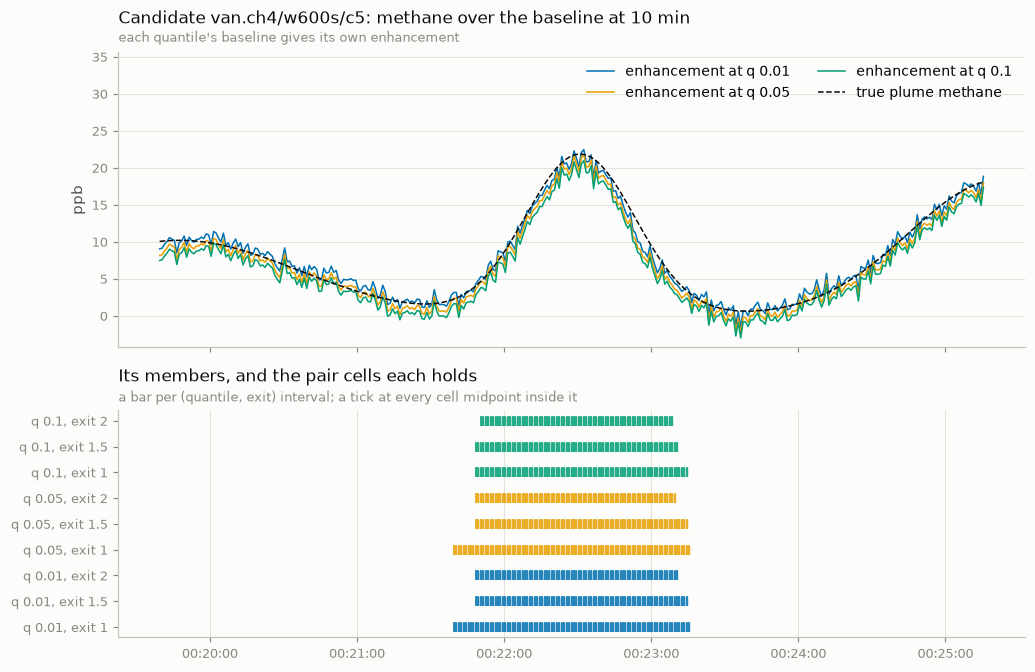

In [3]:
pairs = paired.dataset
mid = pairs.time.values.astype("datetime64[ns]").astype(np.int64)
span = (
    members.start_time.min() - pd.Timedelta("2min"),
    members.end_time.max() + pd.Timedelta("2min"),
)
near = (pairs.time.values >= np.datetime64(span[0])) & (pairs.time.values < np.datetime64(span[1]))

fig, (top, bars) = plt.subplots(
    2, 1, figsize=(9.5, 6.2), sharex=True, gridspec_kw={"height_ratios": [1.3, 1]}
)
colors = {0.01: C1, 0.05: C2, 0.10: C3}
for q, color in colors.items():
    values = pairs[paired.x_name].sel(baseline_window=WINDOW, baseline_quantile=q).values
    top.plot(
        pairs.time.values[near], values[near], color=color, lw=1, label=f"enhancement at q {q:g}"
    )
truth = products["truth"]
top.plot(
    pairs.time.values[near],
    (truth["A"] + truth["B"])[near],
    color=INK,
    ls="--",
    lw=1,
    label="true plume methane",
)
top.set_ylim(top=1.5 * top.get_ylim()[1])  # headroom, so the legend sits above the air
finish(
    top,
    title=f"Candidate {candidate}: methane over the baseline at {WINDOW / 60:g} min",
    sub="each quantile's baseline gives its own enhancement",
    ylab="ppb",
)
top.legend(loc="upper right", ncol=2)

for k, row in enumerate(members.itertuples()):
    s, e = pd.Timestamp(row.start_time), pd.Timestamp(row.end_time)
    color = colors[row.baseline_quantile]
    bars.plot([s, e], [k, k], color=color, lw=6, alpha=0.35, solid_capstyle="butt")
    points = reference_points(mid, s.value, e.value)
    bars.plot(pairs.time.values[points], np.full(len(points), k), "|", color=color, ms=7)
bars.set_yticks(range(len(members)))
bars.set_yticklabels(
    [f"q {r.baseline_quantile:g}, exit {r.exit_multiple:g}" for r in members.itertuples()]
)
finish(
    bars,
    title="Its members, and the pair cells each holds",
    sub="a bar per (quantile, exit) interval; a tick at every cell midpoint inside it",
    grid_axis="x",
)
clock(bars, "%H:%M:%S")
plt.tight_layout()
plt.show()

In [4]:
# The points every member holds, by the loop above, against the fit's count of
# points used (a point is used when both enhancements are finite there).
agree = 0
for row in york_fits.itertuples():
    points = reference_points(
        mid, pd.Timestamp(row.start_time).value, pd.Timestamp(row.end_time).value
    )
    at = dict(baseline_window=row.baseline_window, baseline_quantile=row.baseline_quantile)
    x = pairs[paired.x_name].sel(at).values[points]
    y = pairs[paired.y_name].sel(at).values[points]
    agree += int((np.isfinite(x) & np.isfinite(y)).sum()) == row.n
check(
    "§1 each member's points are the cells whose midpoint its interval holds",
    agree == len(york_fits),
    f"{agree} of {len(york_fits)} members",
)

# On the analyzer's own cells, the midpoint rule is the event index.
state = products["events"]["van"]
mismatched = 0
for key, group in catalog[catalog.species == "ch4"].groupby(
    ["baseline_window", "baseline_quantile", "enter_multiple", "exit_multiple"]
):
    index = (
        state["event_ch4"]
        .sel(
            baseline_window=key[0],
            baseline_quantile=key[1],
            enter_multiple=key[2],
            exit_multiple=key[3],
        )
        .values
    )
    rebuilt = np.full(mid.size, -1)
    for row in group.itertuples():
        rebuilt[
            reference_points(
                mid, pd.Timestamp(row.start_time).value, pd.Timestamp(row.end_time).value
            )
        ] = row.event_number
    mismatched += int((rebuilt != index).sum())
check(
    "§1 on the reference's own cells, midpoint membership is the event index",
    mismatched == 0,
    "at every reading of all 81 sweep points",
)

  ✔ §1 each member's points are the cells whose midpoint its interval holds   [389 of 389 members]


  ✔ §1 on the reference's own cells, midpoint membership is the event index   [at every reading of all 81 sweep points]


**Try it.**

* `WINDOW = 120.0`: 18 candidates instead of 14; the one picked again holds
  nine members, and every check holds.
* `SEED = 2`: the candidate picked has only six members. At the three lowest
  (quantile, exit) pairs its plume is swallowed by a 14-minute event that
  peaks on a far taller plume six minutes earlier, so those events belong to
  that plume's candidate (*absorbed*, `METHODS.md` §6.8). Every check holds.
* `PICK = 0`: the tallest candidate, seven minutes long; its 400-odd points
  crowd into solid bars, which is why the default is a short one.

---
## §2 Two instruments on one clock

A ratio across two instruments needs both gases on the same cells. Pairing
(`tsara.align.pair_species`, `METHODS.md` §1.3, §11.4) puts them on the
**pair clock**: the cells of the wider-supported instrument, the other
averaged onto them, each reading weighted by the time it shares with the
cell, its sigma propagated through the same weights. Nothing is ever copied
onto a narrower cell.

Three things are new in 7c1:

* **The sweep travels.** An enhancement has one version per (window,
  quantile). Each sweep point is paired as if alone: a cell is a pair *there*
  when both gases have a value there, and a row that is a pair at no point is
  dropped (§11.4, "Swept members").
* **Readings ride along** (`carry=`), so that each pair holds the readings'
  own sigma, which is what weighs a fit (§4.3).
* **The pair clock can be chosen**: `native` (the rule above) or a period such
  as `10s`, every value averaged onto it (`ratios.periods`).

Here the reference is a 2 s analyzer's methane ('picarro') and the numerator
the 1 s analyzer's ethane ('aeris'), from the same air.

In [5]:
start_section("§2")
# --- parameters --------------------------------------------------------------
SEED = 1  # which manufactured hour
OFFSET = 0.0  # where the 2 s analyzer's cells start after each even second: 0.0 or 0.5
PERIOD = "native"  # the pair clock: "native" (the wider cells) or a duration such as "10s"
WINDOW = 600.0  # the sweep point drawn below: baseline window (s)
QUANTILE = 0.05  # and quantile

run = two_analyzers(seed=SEED, offset_s=OFFSET, period=PERIOD)
paired = run["paired"]
pairs = paired.dataset
print(f"pair clock: {paired.clock} ({pairs.attrs['tsara_pairing_clock_reason']})")
counts = np.array(pairs.attrs["tsara_pairing_pairs_per_sweep_point"]).reshape(
    pairs.sizes["baseline_window"], pairs.sizes["baseline_quantile"]
)
table = pd.DataFrame(
    counts,
    index=[f"{w / 60:g} min" for w in pairs.baseline_window.values],
    columns=[f"q {q:g}" for q in pairs.baseline_quantile.values],
)
print(f"\npairs at each sweep point (of {paired.n_pairs} rows kept):")
print(table.to_string())
ethane = paired.y_name
print(
    f"\nethane: {pairs[ethane].attrs['tsara_n_readings']} readings behind the pairs, "
    f"borrowed share {pairs[ethane].attrs['tsara_borrowed_share']:.2f}, "
    f"readings in more than one pair {pairs[ethane].attrs['tsara_shared_readings']}"
)

pair clock: picarro (wider cells (2 s vs 1 s))

pairs at each sweep point (of 1799 rows kept):
        q 0.01  q 0.05  q 0.1
2 min        0    1799   1799
10 min    1799    1799   1799
60 min    1799    1799   1799

ethane: 3598 readings behind the pairs, borrowed share 0.00, readings in more than one pair 0


At 2 min and q 0.01 nothing pairs: the 2 s analyzer's 2 min windows hold 60
readings, and a 1st percentile needs 100 (`METHODS.md` §6.4), so its
baseline, and its enhancement, is blank there. Every other sweep point pairs
on its own rows.

The figure takes 90 s around the strongest plume of the ethane-bearing source
A (the recipe knows where it is): the 1 s ethane readings over their
baseline, and the values pairing put on each cell of the clock.

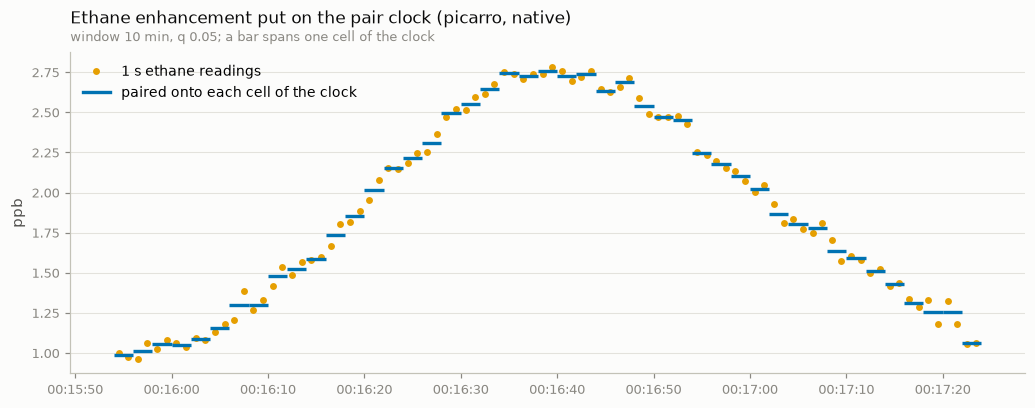

In [6]:
peak = START + pd.Timedelta(seconds=int(np.argmax(run["truth"]["A"])))
lo, hi = peak - pd.Timedelta("45s"), peak + pd.Timedelta("45s")

aeris = run["states"]["aeris"]
reading = aeris["enhancement_c2h6"].sel(baseline_window=WINDOW, baseline_quantile=QUANTILE)
shown = (aeris.time.values >= np.datetime64(lo)) & (aeris.time.values < np.datetime64(hi))
cells = pairs.time_bnds.values
inside = (cells[:, 0] >= np.datetime64(lo)) & (cells[:, 1] <= np.datetime64(hi))
joined = pairs[ethane].sel(baseline_window=WINDOW, baseline_quantile=QUANTILE).values

fig, ax = plt.subplots(figsize=(9.5, 3.8))
ax.plot(
    aeris.time.values[shown],
    reading.values[shown],
    "o",
    color=C2,
    ms=3.5,
    label="1 s ethane readings",
)
for (start, stop), value in zip(cells[inside], joined[inside]):
    ax.plot([start, stop], [value, value], color=C1, lw=2.2, solid_capstyle="butt")
ax.plot([], [], color=C1, lw=2.2, label="paired onto each cell of the clock")
finish(
    ax,
    title=f"Ethane enhancement put on the pair clock ({paired.clock}, {PERIOD})",
    sub=f"window {WINDOW / 60:g} min, q {QUANTILE:g}; a bar spans one cell of the clock",
    ylab="ppb",
    legend=True,
    loc="upper left",
)
clock(ax, "%H:%M:%S")
plt.tight_layout()
plt.show()

In [7]:
# 1. Every sweep point, swept and alone: the pairing of that point by itself.
alone_ok, compared = True, 0
for i, w in enumerate(pairs.baseline_window.values):
    for j, q in enumerate(pairs.baseline_quantile.values):
        if counts[i, j] == 0:
            continue
        alone = {
            name: state.isel(baseline_window=i, baseline_quantile=j)
            for name, state in run["states"].items()
        }
        single = pair_species(
            alone,
            ("aeris", "enhancement_c2h6"),
            ("picarro", "enhancement_ch4"),
            carry=[("aeris", "c2h6"), ("picarro", "ch4")],
            target=None if PERIOD == "native" else PERIOD,
        ).dataset
        at = pairs.isel(baseline_window=i, baseline_quantile=j)
        here = at.isel(time=np.flatnonzero(np.isfinite(at[ethane].values)))
        for name in single.data_vars:
            alone_ok &= np.array_equal(here[name].values, single[name].values, equal_nan=True)
        compared += 1
check(
    "§2 every sweep point is bit for bit what pairing it alone gives",
    alone_ok,
    f"{compared} sweep points with pairs, every column",
)

# 2. The averaging itself, by the loop in the setup cell, at the drawn sweep point.
bounds = aeris.time_bnds.values.astype("datetime64[ns]").astype(np.int64)
sigma = aeris["sigma_rand_c2h6"].values
cell_ns = cells.astype("datetime64[ns]").astype(np.int64)
worst_value = worst_sigma = 0.0
for k in np.flatnonzero(np.isfinite(joined)):
    near = slice(
        max(0, np.searchsorted(bounds[:, 1], cell_ns[k, 0]) - 1),
        np.searchsorted(bounds[:, 0], cell_ns[k, 1]) + 1,
    )
    value, value_sigma = reference_join(
        bounds[near], reading.values[near], sigma[near], *cell_ns[k]
    )
    worst_value = max(worst_value, abs(value - joined[k]))
    worst_sigma = max(worst_sigma, abs(value_sigma - pairs["sigma_rand_c2h6"].values[k]))
check(
    "§2 each paired ethane value is the overlap-weighted mean of the readings in its cell",
    worst_value < 1e-9,
    f"largest difference {worst_value:.1e} ppb",
)
check(
    "§2 the carried reading sigma is sqrt(sum w^2 sigma^2) / sum w over the same readings",
    worst_sigma < 1e-12,
    f"largest difference {worst_sigma:.1e} ppb",
)

  ✔ §2 every sweep point is bit for bit what pairing it alone gives   [8 sweep points with pairs, every column]
  ✔ §2 each paired ethane value is the overlap-weighted mean of the readings in its cell   [largest difference 0.0e+00 ppb]
  ✔ §2 the carried reading sigma is sqrt(sum w^2 sigma^2) / sum w over the same readings   [largest difference 0.0e+00 ppb]


**Try it.**

* `OFFSET = 0.5`: the 2 s cells now straddle the 1 s readings. Each cell
  takes half of a reading at each end, so a quarter of each paired value rests
  on air outside its cell (borrowed share 0.25), and 1,798 of the 3,599
  readings sit in two pairs (`tsara_shared_readings`). The averaging checks
  still hold: the overlap weights carry it.
* `PERIOD = "10s"`: both gases are averaged onto a 10 s clock (`explicit`):
  360 rows instead of 1,799, a fifth as many at every sweep point, which is
  what starves a short event of points.

---
## §3 One member's line, and what a fit stores

Each member gets two lines through its points, the numerator's enhancement
against the reference's (`METHODS.md` §4):

* **York's**, weighted by both axes' declared random sigma (here 0.7 ppb
  methane, 0.05 ppb ethane, the *readings'* sigma, §4.3), the preferred
  ratio: least squares reads a noisy x's slope low (regression dilution).
* **Least squares**, kept for its familiar diagnostics.

Beside each line the fit stores every number a gate will read (§5.3), so that
gating is a threshold applied later, never a refit:

| number | what it is |
|---|---|
| `peak_z`, `candidate_peak_z` | the member's own peak height in clean spreads, and its candidate's tallest |
| `n` | the points used (both enhancements finite) |
| `signal` | the reference's swing inside the member over its noise, √max(0, var(Δx) / mean(σx²) − 1) |
| `mswd`, `dof` | York's mean squared weighted deviation and its n − 2 degrees of freedom; about 1 when the declared noise explains the scatter |
| `plateau_slope`, `plateau_mswd`, `plateau_dof` | York again over twice the member's width, centred on it (§5) |

Here, the tallest member at one sweep point whose air is at least 99.9 % one
source (the recipe knows each source's share of every member's methane), or
the tallest mixture.

In [8]:
start_section("§3")
# --- parameters --------------------------------------------------------------
SEED = 1  # which manufactured hour
WINDOW = 600.0  # the sweep point: baseline window (s),
QUANTILE = 0.05  # quantile,
EXIT = 1.0  # and exit
CHOOSE = "A"  # "A": a member of source A (ethane/methane 0.05); "B": of source B (0); "mixture"
PURITY = 0.999  # for "A" or "B": the least share of the member's true methane its source holds

products = chain(seed=SEED)
fits, pairs, truth = products["fits"], products["paired"].dataset, products["truth"]
share, largest = source_share(fits, truth, pairs)
wanted = {
    "A": share >= PURITY,
    "B": share <= 1 - PURITY,
    "mixture": (share > 0.05) & (share < 0.95),
}[CHOOSE]
found = fits[
    (fits.method == "york")
    & (fits.status == "OK")
    & wanted
    & (fits.baseline_window == WINDOW)
    & (fits.baseline_quantile == QUANTILE)
    & (fits.exit_multiple == EXIT)
].sort_values("peak_z", ascending=False)
if found.empty:
    raise ValueError(
        f"no {CHOOSE} member at this sweep point; try another SEED, sweep point or PURITY"
    )
pick = found.iloc[0]
both = fits[fits.event_id == pick.event_id].set_index("method")
shown = [
    "n",
    "signal",
    "peak_z",
    "candidate_peak_z",
    "slope",
    "slope_sigma",
    "intercept",
    "mswd",
    "dof",
    "r_squared",
    "plateau_slope",
    "plateau_mswd",
    "plateau_dof",
    "status",
]
truth_ratio = {"A": RATIO_A, "B": RATIO_B}.get(CHOOSE)
print(
    f"member {pick.event_id}: {CHOOSE}, source A's share of its methane "
    f"{share[pick.name]:.4f}, true ratio {truth_ratio if truth_ratio is not None else 'none'}\n"
)
print(both[shown].T.to_string())

member van.ch4/w600s/q0.05/e3/x1/12: A, source A's share of its methane 1.0000, true ratio 0.05

method                  ols       york
n                       191        191
signal            12.926138  12.926138
peak_z            25.653342  25.653342
candidate_peak_z  27.411018  27.411018
slope              0.046769   0.047221
slope_sigma        0.000608    0.00048
intercept          0.063213   0.056949
mswd               1.617156   1.617156
dof                     189        189
r_squared          0.969005   0.969005
plateau_slope      0.050253   0.050253
plateau_mswd       3.049159   3.049159
plateau_dof             342        342
status                   OK         OK


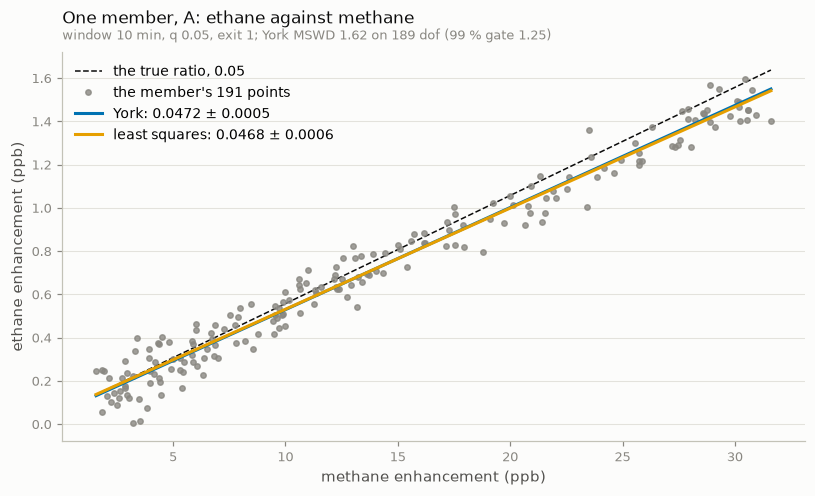

  ✔ §3 the stored lines are York's and least squares' on the member's points alone   [slope, intercept, sigma, r2]
  ✔ §3 the signal is sqrt(max(0, var(dx)/mean(sigma_x^2) - 1)), variance on n - 1   [12.93]
  ✔ §3 dof is n - 2, and least squares' row carries York's MSWD
  ✔ §3 every row carries its candidate's tallest member's height   [44 candidates]


In [9]:
mid = pairs.time.values.astype("datetime64[ns]").astype(np.int64)
points = reference_points(
    mid, pd.Timestamp(pick.start_time).value, pd.Timestamp(pick.end_time).value
)
at = dict(baseline_window=WINDOW, baseline_quantile=QUANTILE)
x = pairs["enhancement_ch4"].sel(at).values[points]
y = pairs["enhancement_c2h6"].sel(at).values[points]
sx, sy = pairs["sigma_rand_ch4"].values[points], pairs["sigma_rand_c2h6"].values[points]

fig, ax = plt.subplots(figsize=(7.5, 4.6))
if truth_ratio is not None:
    ax.plot(
        grid := np.linspace(np.nanmin(x), np.nanmax(x), 2),
        pick.intercept + truth_ratio * grid,
        color=INK,
        ls="--",
        lw=1,
        label=f"the true ratio, {truth_ratio:g}",
    )
ax.plot(x, y, "o", color=MUTED, ms=3.5, alpha=0.8, label=f"the member's {len(x)} points")
grid = np.linspace(np.nanmin(x), np.nanmax(x), 2)
for method, color in (("york", C1), ("ols", C2)):
    line = both.loc[method]
    name = "York" if method == "york" else "least squares"
    ax.plot(
        grid,
        line.intercept + line.slope * grid,
        color=color,
        lw=2,
        label=f"{name}: {line.slope:.4f} ± {line.slope_sigma:.4f}",
    )
finish(
    ax,
    title=f"One member, {CHOOSE}: ethane against methane",
    sub=f"window {WINDOW / 60:g} min, q {QUANTILE:g}, exit {EXIT:g}; "
    f"York MSWD {pick.mswd:.2f} on {pick.dof} dof (99 % gate {float(mswd_gate(pick.dof)):.2f})",
    xlab="methane enhancement (ppb)",
    ylab="ethane enhancement (ppb)",
    legend=True,
    loc="upper left",
)
plt.tight_layout()
plt.show()

# The stored lines are the estimators' own on these points alone, bit for bit.
alone = {"york": york(x, y, sx, sy), "ols": ols(x, y, sx, sy)}
same = all(
    np.array_equal(both.loc[m, f], getattr(alone[m], f)[0], equal_nan=True)
    for m in alone
    for f in ("slope", "intercept", "slope_sigma", "r_squared")
)
check(
    "§3 the stored lines are York's and least squares' on the member's points alone",
    same,
    "slope, intercept, sigma, r2",
)
used = np.isfinite(x) & np.isfinite(y) & np.isfinite(sx)
signal = math.sqrt(max(0.0, np.var(x[used], ddof=1) / np.mean(sx[used] ** 2) - 1))
check(
    "§3 the signal is sqrt(max(0, var(dx)/mean(sigma_x^2) - 1)), variance on n - 1",
    math.isclose(pick.signal, signal, rel_tol=1e-12),
    f"{signal:.2f}",
)
check(
    "§3 dof is n - 2, and least squares' row carries York's MSWD",
    pick.dof == pick.n - 2 and both.loc["ols", "mswd"] == pick.mswd,
)
york_rows = fits[fits.method == "york"]
check(
    "§3 every row carries its candidate's tallest member's height",
    (york_rows.candidate_peak_z == york_rows.groupby("candidate_id").peak_z.transform("max")).all(),
    f"{york_rows.candidate_id.nunique()} candidates",
)

Read the York line against the dashed truth, and its MSWD against the gate.
On the default member, both miss although its air is one source: the slope
sits several of its σ below 0.05, and the MSWD is above the gate. Neither is
the line's fault. It is the baseline's error across the member, which no σ
here holds; §6 measures it, and shows the same member fitted on the true
background. Other members may not miss; the Try-its below pick some.

**Try it.**

* `CHOOSE = "mixture"`: a member whose methane is 31 % source A. York reads
  0.011 at an MSWD of 61, fifty times its gate: a slope between the two
  sources' ratios, which is no source's ratio, and the gate says so.
* `CHOOSE = "B"`: source B emits no ethane, and York reads −0.0008 ± 0.0008,
  consistent with 0. An upper limit is a result (`METHODS.md` §5.5): the
  interval says how much ethane this source can have.
* `WINDOW = 120.0` or `3600.0`: the same plume (it peaks at 00:56:58.5 at
  every window) reads 0.0486 and 0.0468, its MSWD above the gate each time:
  the miss follows the plume's air, not the window.

---
## §4 The slope's sigma, widened

York's σ assumes each point's error is independent of the next. A 1 s
analyzer whose cell flushes over a few seconds breaks that: consecutive
errors persist, the points carry less information than their count, and
York's σ promises too much. The MSWD cannot see it, because each point's
scatter is still the declared noise (`METHODS.md` §4.5, finding 4). So the
stage widens York's σ twice (§5.4):

σ_widened = σ · √(N / N_eff) · √max(1, MSWD)

* **√(N / N_eff)**, the **persistence factor**, from the decorrelation time τ
  declared on the readings: N_eff is what N correlated points are worth. With
  no τ declared it is 1, and the fit says so.
* **√max(1, MSWD)**, the **Birge factor**: widens σ when the scatter is larger
  than the declared noise explains, never narrows it.

This section studies the line alone, apart from the baseline (§6 is about the
baseline): it hands the fit enhancements made directly, many plumes of one
true ratio with errors that persist, and asks how far the slopes really
scatter against what each σ promises. A σ that keeps its promise covers the
truth in 95 % of fits at ±2σ.

In [10]:
start_section("§4")
# --- parameters --------------------------------------------------------------
RHO = (
    0.7  # lag-one correlation of the errors on 1 s readings (0 = independent); tau = -1 s / ln(RHO)
)
DECLARE_TAU = True  # declare that tau to the fit, as a manifest would
N_PLUMES = 800  # plumes, each fitted once
SEED = 3

rng = np.random.default_rng(SEED)
length, gap = 60, 20  # each plume read once a second for 60 s, 20 s apart
t = np.arange(length) - length / 2
true_ch4 = 60.0 * np.exp(-(t**2) / (2 * 10.0**2))  # a 60 ppb plume, 10 s wide


def persistent(scale):
    """AR(1) errors of stationary sd `scale`, one row per plume, from the textbook recursion."""
    noise = np.empty((N_PLUMES, length))
    noise[:, 0] = rng.normal(0, scale, N_PLUMES)
    kick = rng.normal(0, scale * math.sqrt(1 - RHO**2), (N_PLUMES, length))
    for k in range(1, length):
        noise[:, k] = RHO * noise[:, k - 1] + kick[:, k]
    return noise


block = length + gap
dx, dy = np.full(N_PLUMES * block, np.nan), np.full(N_PLUMES * block, np.nan)
inside = (np.arange(N_PLUMES)[:, None] * block + np.arange(length)).ravel()
dx[inside] = (true_ch4 + persistent(3.0)).ravel()
dy[inside] = (RATIO_A * true_ch4 + persistent(0.3)).ravel()
tau_s = -1.0 / math.log(RHO) if RHO > 0 else None
pairs = pairs_by_hand(dx, dy, 3.0, 0.3, tau=f"{tau_s:.6f}s" if (DECLARE_TAU and tau_s) else None)
catalog = catalog_by_hand([(k * block, k * block + length) for k in range(N_PLUMES)])
fits = member_fits(
    pairs,
    catalog,
    HAND_COLUMNS,
    reference="van.ch4",
    numerator="van.c2h6",
    period="native",
    methods=("york",),
)

error = fits.slope - RATIO_A
spread = 1.4826 * np.median(np.abs(error - np.median(error)))  # robust: weak fits have wild misses
for name, sigma in (("as it comes", fits.slope_sigma), ("widened", fits.slope_sigma_widened)):
    one, two = np.mean(np.abs(error) <= sigma), np.mean(np.abs(error) <= 2 * sigma)
    print(
        f"{name:12s}: slopes' spread / median sigma {spread / np.median(sigma):.2f}, "
        f"truth within ±1 sigma {one:.2f}, ±2 sigma {two:.2f}"
    )
print(
    f"persistence factor {fits.persistence_factor.iloc[0]:.3f}; Birge factor above 1 on "
    f"{np.mean(fits.birge_factor > 1):.0%} of fits"
)

as it comes : slopes' spread / median sigma 2.24, truth within ±1 sigma 0.32, ±2 sigma 0.61
widened     : slopes' spread / median sigma 0.95, truth within ±1 sigma 0.70, ±2 sigma 0.97
persistence factor 2.325; Birge factor above 1 on 27% of fits


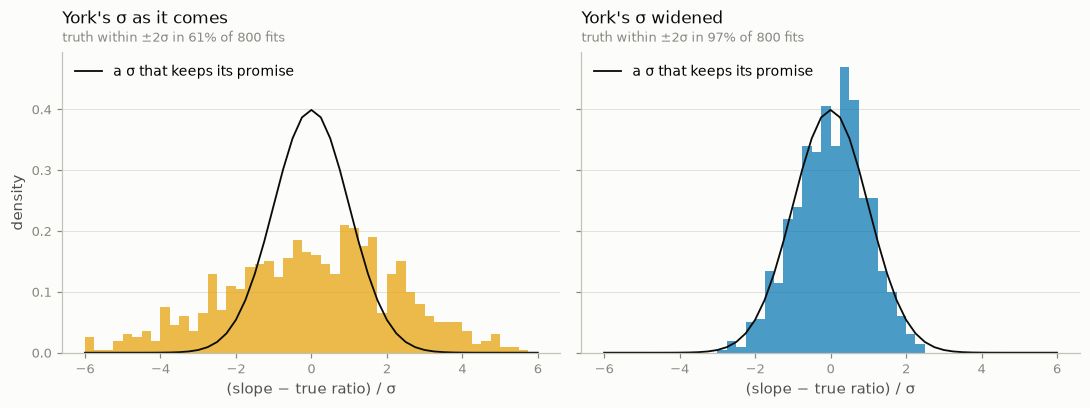

  ✔ §4 the persistence factor is sqrt(N / N_eff), N_eff by its sum (1 with no tau declared)   [2.325]
  ✔ §4 the Birge factor is sqrt(max(1, MSWD)), never below 1
  ✔ §4 with tau declared, the widened sigma covers the truth in at least 90 % of fits at ±2 sigma   [honest, or on the safe side]


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
bins = np.linspace(-6, 6, 49)
curve = np.exp(-0.5 * bins**2) / math.sqrt(2 * math.pi)
for ax, (name, sigma, color) in zip(
    axes, (("as it comes", fits.slope_sigma, C2), ("widened", fits.slope_sigma_widened, C1))
):
    ax.hist(np.clip(error / sigma, -6, 6), bins=bins, density=True, color=color, alpha=0.7)
    ax.plot(bins, curve, color=INK, lw=1.2, label="a σ that keeps its promise")
    within = np.mean(np.abs(error) <= 2 * sigma)
    finish(
        ax,
        title=f"York's σ {name}",
        sub=f"truth within ±2σ in {within:.0%} of {N_PLUMES} fits",
        xlab="(slope − true ratio) / σ",
        legend=True,
        loc="upper left",
    )
axes[0].set_ylabel("density")
plt.tight_layout()
plt.show()

# The persistence factor, from the definition of N_eff by its sum, for the first fit.
first = fits.iloc[0]
# (the tau the fit read: declared as a string of six decimals)
declared = first.tau_s
expected = (
    math.sqrt(first.n / reference_n_effective(int(first.n), 1.0, declared))
    if np.isfinite(declared)
    else 1.0
)
check(
    "§4 the persistence factor is sqrt(N / N_eff), N_eff by its sum (1 with no tau declared)",
    math.isclose(first.persistence_factor, expected, rel_tol=1e-9),
    f"{expected:.3f}",
)
check(
    "§4 the Birge factor is sqrt(max(1, MSWD)), never below 1",
    np.allclose(fits.birge_factor, np.sqrt(np.maximum(1.0, fits.mswd)), rtol=1e-12, atol=0),
)
check(
    "§4 with tau declared, the widened sigma covers the truth in at least 90 % of fits at ±2 sigma",
    not DECLARE_TAU or np.mean(np.abs(error) <= 2 * fits.slope_sigma_widened) >= 0.9,
    "honest, or on the safe side" if DECLARE_TAU else "not asked: tau not declared",
)

At the defaults (ρ 0.7, τ 2.8 s), York's σ as it comes promises 2.2 times
less spread than the slopes have and covers the truth in 61 % of fits at
±2σ; widened, the spread is 0.95 of the σ and the coverage 97 %.

**Try it.**

* `RHO = 0.0`: independent errors. The persistence factor is exactly 1, and
  York's σ as it comes is already honest (spread 1.02 of it, 96 % at ±2σ).
* `DECLARE_TAU = False`: the errors still persist, but nobody said so. The
  persistence factor is 1 and the widened σ is as tight as the raw one (62 % at
  ±2σ): τ has to be declared, by a manifest or by a survey that measures it.
* `RHO = 0.9` (τ 9.5 s): the widening errs on the safe side, the spread 0.74
  of the widened σ and the truth inside ±2σ in every fit.

---
## §5 The gates, and the plateau's trade

A gate never changes a fit; it decides whether the fit counts. So the fit
table stores the numbers (§3) and a gate is a threshold applied afterwards.
Each gate in `ratios.gates` is a *list*, swept like a window, at no cost in
refitting (`METHODS.md` §5.3):

| gate | reads | default |
|---|---|---|
| height | `candidate_peak_z`, the candidate's tallest member | 5 |
| points | `n` | 8 |
| signal | `signal` | 2 |
| one source | York's `mswd` against the 99 % χ² quantile for its `dof` | 0.99 |
| plateau | `plateau_mswd` against the same quantile for `plateau_dof` | off (1) |

The **plateau** refits each member over twice its width, centred on it. The
hope: a member that only *looks* like one source, because its interval stops
short of a neighbour, fails once the window reaches the neighbour. Measured
here on six hours of two sources, the recipe saying which members are one
source (at least 95 % of their methane from one) and which are mixtures.

In [12]:
start_section("§5")
# --- parameters --------------------------------------------------------------
SEED = 1
HOURS = 6.0  # a longer record, for enough members
MIN_PEAK_Z = 5.0  # height gate
MIN_SIGNAL = 2.0  # signal gate
PLATEAU_PROBABILITY = 0.99  # the plateau gate when on

products = chain(seed=SEED, hours=HOURS)
fits, pairs = products["fits"], products["paired"].dataset
share, largest = source_share(fits, products["truth"], pairs)
york_rows = fits.assign(kind=kind_of(share, largest))
york_rows = york_rows[york_rows.method == "york"]
eligible = york_rows[
    (york_rows.status == "OK")
    & (york_rows.candidate_peak_z >= MIN_PEAK_Z)
    & (york_rows.n >= 8)
    & (york_rows.signal >= MIN_SIGNAL)
]
one_source = eligible.mswd <= mswd_gate(eligible.dof)
plateau = eligible.plateau_mswd <= mswd_gate(eligible.plateau_dof, PLATEAU_PROBABILITY)
single = eligible.kind.isin(["A", "B"])
mixture = eligible.kind == "mixture"
rules = {
    "height, points and signal only": np.ones(len(eligible), bool),
    "+ one source (the default)": one_source.to_numpy(),
    "+ one source + plateau": (one_source & plateau).to_numpy(),
}
rows = []
for name, keep in rules.items():
    kept_single, kept_mixture = (keep & single).sum(), (keep & mixture).sum()
    rows.append(
        {
            "rule": name,
            "single-source members kept": f"{kept_single} ({kept_single / single.sum():.0%})",
            "mixtures kept": f"{kept_mixture} ({kept_mixture / mixture.sum():.0%})",
        }
    )
print(
    f"{len(eligible)} members pass height, points and signal: "
    f"{single.sum()} single-source, {mixture.sum()} mixtures\n"
)
print(pd.DataFrame(rows).to_string(index=False))

1716 members pass height, points and signal: 854 single-source, 862 mixtures

                          rule single-source members kept mixtures kept
height, points and signal only                 854 (100%)    862 (100%)
    + one source (the default)                  652 (76%)       44 (5%)
        + one source + plateau                  335 (39%)        4 (0%)


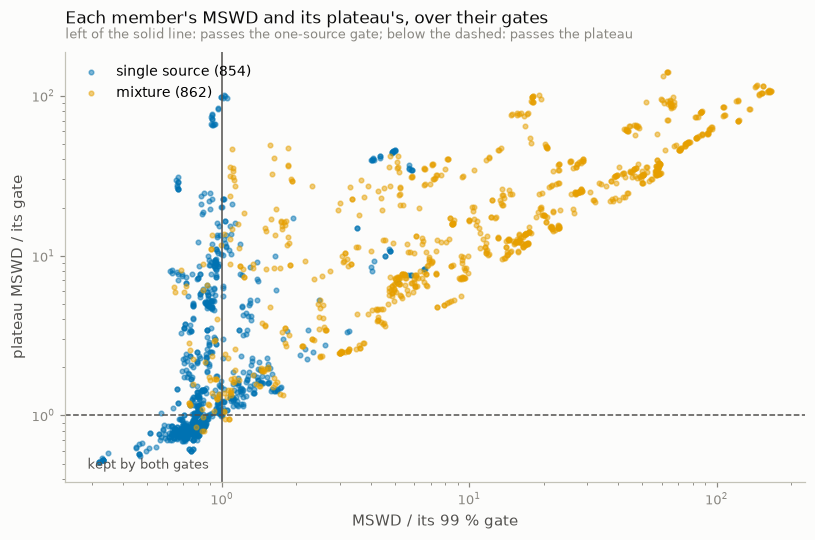

  ✔ §5 the stored plateau is York's own over twice the member's width, centred on it   [30 members]
  ✔ §5 the one-source gate keeps a larger share of single-source members than of mixtures   [76% against 5%]


In [13]:
fig, ax = plt.subplots(figsize=(7.5, 5))
x = eligible.mswd / mswd_gate(eligible.dof)
y = eligible.plateau_mswd / mswd_gate(eligible.plateau_dof, PLATEAU_PROBABILITY)
ax.scatter(x[single], y[single], s=9, color=C1, alpha=0.5, label=f"single source ({single.sum()})")
ax.scatter(x[mixture], y[mixture], s=9, color=C2, alpha=0.5, label=f"mixture ({mixture.sum()})")
ax.axvline(1, color=INK2, lw=1)
ax.axhline(1, color=INK2, lw=1, ls="--")
ax.set_xscale("log")
ax.set_yscale("log")
ax.text(0.03, 0.03, "kept by both gates", transform=ax.transAxes, color=INK2, fontsize=8.5)
finish(
    ax,
    title="Each member's MSWD and its plateau's, over their gates",
    sub="left of the solid line: passes the one-source gate; below the dashed: passes the plateau",
    xlab="MSWD / its 99 % gate",
    ylab="plateau MSWD / its gate",
    legend=True,
    loc="upper left",
    grid_axis=None,
)
plt.tight_layout()
plt.show()

# The stored plateau is York's own over twice the member's width, centred, for a sample of members.
mid = pairs.time.values.astype("datetime64[ns]").astype(np.int64)
same, sample = True, eligible.sample(30, random_state=0) if len(eligible) >= 30 else eligible
for row in sample.itertuples():
    start, stop = pd.Timestamp(row.start_time).value, pd.Timestamp(row.end_time).value
    centre, half = start + (stop - start) // 2, stop - start
    points = reference_points(mid, centre - half, centre + half)
    at = dict(baseline_window=row.baseline_window, baseline_quantile=row.baseline_quantile)
    line = york(
        pairs["enhancement_ch4"].sel(at).values[points],
        pairs["enhancement_c2h6"].sel(at).values[points],
        pairs["sigma_rand_ch4"].values[points],
        pairs["sigma_rand_c2h6"].values[points],
    )
    same &= np.array_equal(row.plateau_slope, line.slope[0]) and np.array_equal(
        row.plateau_mswd, line.mswd[0]
    )
check(
    "§5 the stored plateau is York's own over twice the member's width, centred on it",
    same,
    f"{len(sample)} members",
)
check(
    "§5 the one-source gate keeps a larger share of single-source members than of mixtures",
    one_source[single].mean() > one_source[mixture].mean(),
    f"{one_source[single].mean():.0%} against {one_source[mixture].mean():.0%}",
)

The plateau does what it was meant to: most of the mixtures the one-source
gate lets through fail it. But it fails about half of the good single-source
members too (the many blue points above the dashed line), because a window
twice as wide reaches a neighbour as often as it reaches the rest of a
mixture: it rejects *a neighbour nearby* as readily as *a mixture*. So its
numbers are stored and its gate is off by default; the sweep summary (7c2)
will show the trade with the gate on and off side by side
(`ratios.gates.plateau_probability: [0.99, 1.0]`).

**Try it.**

* `MIN_SIGNAL = 0.0`: 165 weaker members join (136 single-source, 29
  mixtures), and the one-source gate now lets 8 % of the mixtures through
  instead of 5 %: where methane barely swings, the MSWD has little to judge
  by. That is what the signal gate is for.
* `PLATEAU_PROBABILITY = 0.9999`: a looser plateau keeps 45 % of the
  single-source members instead of 39 %, and 1 % of the mixtures instead of
  under 1 %: the trade moves, it does not go away.

---
## §6 What the widened σ does not hold: the baseline's error

§4 handed the fit its enhancements directly, and the widened σ kept its
promise. In the real chain the enhancements are readings minus a **baseline**,
a low quantile over a window, and the baseline has an error of its own. The
fit's weights are the readings' σ (§4.3), on the reasoning that the baseline's
error is shared by every point of an event, so that the line's intercept
absorbs it. That holds when the baseline's error is the same across the
member. It does not hold when the background wanders between the baseline's
window and the event, differently in each gas: then the error changes along
the member, bends the line a little, and moves its slope.

The test: the same members, fitted twice, once on the package's baseline and
once on the **true** background the recipe kept, and how often each widened σ
covers the true ratio. Members at least 99.9 % one source, passing every
gate.

In [14]:
start_section("§6")
# --- parameters --------------------------------------------------------------
SEED = 1
HOURS = 6.0
WALK_CH4 = 30.0  # how far the methane background wanders, ppb a day (0: flat)
WALK_C2H6 = 0.6  # and the ethane background
PURITY = 0.999  # the least share of a member's true methane one source holds

products = chain(seed=SEED, hours=HOURS, walk_ch4=WALK_CH4, walk_c2h6=WALK_C2H6)
stream, truth, pairs = products["stream"], products["truth"], products["paired"].dataset
on_baseline = products["fits"]
on_baseline = on_baseline[on_baseline.method == "york"]

# The same pairs, the enhancements replaced by the readings minus the true background.
true_pairs = pairs.copy()
for column, reading, background in (
    ("enhancement_ch4", "ch4", "background_ch4"),
    ("enhancement_c2h6", "c2h6", "background_c2h6"),
):
    exact = (stream[reading].values - truth[background])[:, None, None]
    true_pairs[column] = (
        pairs[column].dims,
        np.broadcast_to(exact, pairs[column].shape).copy(),
        pairs[column].attrs,
    )
on_truth = member_fits(
    true_pairs,
    products["catalog"],
    PairColumns("enhancement_c2h6", "enhancement_ch4", "c2h6", "ch4"),
    reference="van.ch4",
    numerator="van.c2h6",
    period="native",
    methods=("york",),
)

share, _ = source_share(on_baseline, truth, pairs)
results = {}
for name, fits in (("the package's baseline", on_baseline), ("the true background", on_truth)):
    fits = fits.reset_index(drop=True)
    pure = (share >= PURITY) | (share <= 1 - PURITY)
    keep = (
        pure
        & (fits.status == "OK")
        & (fits.candidate_peak_z >= 5)
        & (fits.n >= 8)
        & (fits.signal >= 2)
        & (fits.mswd <= mswd_gate(fits.dof))
    ).to_numpy()
    truth_ratio = np.where(share[keep] >= 0.5, RATIO_A, RATIO_B)
    error = (fits.slope[keep] - truth_ratio) / fits.slope_sigma_widened[keep]
    results[name] = error
    covered = np.mean(np.abs(error) <= 2)
    robust = 1.4826 * np.median(np.abs(error - np.median(error)))
    print(
        f"on {name:23s}: {keep.sum():4d} members, the truth within ±2 sigma in {covered:.0%}, "
        f"errors' robust spread {robust:.2f} sigma, median {np.median(error):+.2f} sigma"
    )

on the package's baseline :  443 members, the truth within ±2 sigma in 75%, errors' robust spread 1.68 sigma, median -0.11 sigma
on the true background    :  570 members, the truth within ±2 sigma in 94%, errors' robust spread 0.89 sigma, median +0.20 sigma


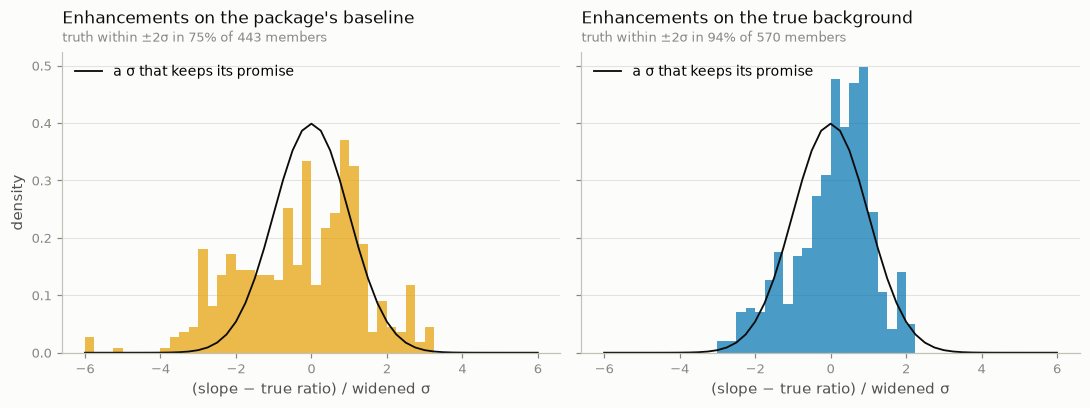

  ✔ §6 on the true background, the widened sigma is honest for single-source members   [spread 0.89 sigma, 94% within ±2 sigma, 570 members]


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
bins = np.linspace(-6, 6, 49)
curve = np.exp(-0.5 * bins**2) / math.sqrt(2 * math.pi)
for ax, (name, error), color in zip(axes, results.items(), (C2, C1)):
    ax.hist(np.clip(error, -6, 6), bins=bins, density=True, color=color, alpha=0.7)
    ax.plot(bins, curve, color=INK, lw=1.2, label="a σ that keeps its promise")
    finish(
        ax,
        title=f"Enhancements on {name}",
        sub=f"truth within ±2σ in {np.mean(np.abs(error) <= 2):.0%} of {len(error)} members",
        xlab="(slope − true ratio) / widened σ",
        legend=True,
        loc="upper left",
    )
axes[0].set_ylabel("density")
plt.tight_layout()
plt.show()

error = results["the true background"]
spread = 1.4826 * np.median(np.abs(error - np.median(error)))
check(
    "§6 on the true background, the widened sigma is honest for single-source members",
    len(error) >= 50 and 0.8 <= spread <= 1.25 and np.mean(np.abs(error) <= 2) >= 0.88,
    f"spread {spread:.2f} sigma, {np.mean(np.abs(error) <= 2):.0%} within ±2 sigma, "
    f"{len(error)} members",
)

On the true background the widened σ keeps its promise; on the package's
baseline the same kind of member scatters about one and a half times as far
as its σ says. (The histograms are lumpy because a candidate's members share
their air and miss together; counted one per candidate the coverage is about
the same, `METHODS.md` §5.4.) The fits are honest about what they model, the readings' own
noise. What no σ here holds is the baseline's error across a member, and the
MSWD barely sees it, since a slowly varying error bends a line more than it
scatters it. §3's default member is one of these: refitted on the true
background of its hour, it reads 0.0496 at an MSWD of 1.22, inside its gate
(measured when this notebook was built).

This is 7c2's to repair (`METHODS.md` §5.4; CLAUDE.md, MUST-handle (s)): a
ratio's combined uncertainty must add the baseline's error, and 7c2's Monte
Carlo must show that it does. Until then, a ratio's interval on wandering air
is about one and a half times too narrow.

**Try it.**

* `WALK_CH4 = 0.0` and `WALK_C2H6 = 0.0`: flat backgrounds. Most of the gap
  closes: the package's baseline now covers about 90 %. What is left is the
  baseline's own sampling error.
* `PURITY = 0.95`: members up to 5 % from the other source join. On the true
  background coverage falls from 94 % to 90 %, since such a member is a little
  mixed; on the package's baseline it stays near 74 %.

---
## Scoreboard

Every check printed above, gathered: each line a claim about TSARA, compared
as it ran against a reference written independently in this notebook or the
truth the recipe manufactured.

In [16]:
held = sum(ok for ok, _ in CHECKS.values())
print(f"{held} of {len(CHECKS)} checks hold\n")
for claim, (ok, detail) in CHECKS.items():
    print(f"  {'✔' if ok else '✘'} {claim}" + (f"   [{detail}]" if detail else ""))

17 of 17 checks hold

  ✔ §1 the members are the distinct (candidate, quantile, exit) intervals, each its lowest entry   [389 members]
  ✔ §1 entry copies hold one interval   [389 (candidate, quantile, exit) groups]
  ✔ §1 each member's points are the cells whose midpoint its interval holds   [389 of 389 members]
  ✔ §1 on the reference's own cells, midpoint membership is the event index   [at every reading of all 81 sweep points]
  ✔ §2 every sweep point is bit for bit what pairing it alone gives   [8 sweep points with pairs, every column]
  ✔ §2 each paired ethane value is the overlap-weighted mean of the readings in its cell   [largest difference 0.0e+00 ppb]
  ✔ §2 the carried reading sigma is sqrt(sum w^2 sigma^2) / sum w over the same readings   [largest difference 0.0e+00 ppb]
  ✔ §3 the stored lines are York's and least squares' on the member's points alone   [slope, intercept, sigma, r2]
  ✔ §3 the signal is sqrt(max(0, var(dx)/mean(sigma_x^2) - 1)), variance on n - 1   [12.93